# Chapitre 8 - Cours 3 : bagging, moyennage de modèles, stacking et bumping

Les deux premiers notebooks utilisaient le bootstrap pour **mesurer** l'incertitude. Ici
(sections 8.7 à 8.9 du livre), on s'en sert pour **améliorer** les prédictions :

1. le **bagging** (*bootstrap aggregating*) : moyenner un modèle réajusté sur des
   échantillons bootstrap (figures 8.9 à 8.12) ;
2. le **moyennage bayésien de modèles** et le **stacking** : combiner des modèles
   différents avec des poids bien choisis ;
3. le **bumping** : utiliser le bootstrap pour explorer l'espace des modèles et trouver
   un meilleur modèle unique (figure 8.13).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. Le bagging (section 8.7)

On dispose de données $Z = \{(x_1, y_1), \dots, (x_N, y_N)\}$ et d'une méthode qui
fournit une prédiction $\hat f(x)$. Pour chaque échantillon bootstrap $Z^{*b}$
($b = 1, \dots, B$), on réajuste la méthode, ce qui donne $\hat f^{*b}(x)$, puis on
moyenne :

$$\hat f_{\text{bag}}(x) = \frac1B\sum_{b=1}^B \hat f^{*b}(x). \qquad \text{(éq. (8.51))}$$

Si $\hat P$ désigne la loi empirique (masse $1/N$ sur chaque couple $(x_i, y_i)$), le
« vrai » estimateur bagging est $E_{\hat P}\hat f^*(x)$ ; (8.51) en est une
approximation de Monte-Carlo, qui converge quand $B \to \infty$.

> **Intuition.** Moyenner réduit la **variance** sans changer (beaucoup) le biais. Le
> bagging n'a d'intérêt que si $\hat f$ dépend de façon **non linéaire** ou
> **instable** des données : pour un lisseur linéaire, il ne change presque rien
> (exercice 8.4).

### Bagging d'un classifieur : votes ou probabilités ?

Pour un problème à $K$ classes, on associe au classifieur $\hat G(x)$ le vecteur
indicateur $\hat f(x)$ (un 1 à la classe prédite, des 0 ailleurs). Alors
$\hat f_{\text{bag}}(x) = (p_1(x), \dots, p_K(x))$ où $p_k(x)$ est la **proportion
d'arbres qui votent** pour la classe $k$, et le classifieur bagging est
$\hat G_{\text{bag}}(x) = \arg\max_k \hat f_{\text{bag}}(x)$ (**vote majoritaire**, ou
consensus).

Les proportions de votes **ne sont pas** des estimations des probabilités de classe : si
$\Pr(Y = 1\mid x) = 0{,}75$ et que tous les classifieurs prédisent 1, on obtient
$p_1(x) = 1$. Si le classifieur fournit lui-même des probabilités (pour un arbre : les
proportions de classes dans la feuille), on peut plutôt **moyenner ces probabilités**.

### Exemple : arbres sur données simulées (section 8.7.1)

* $N = 30$ observations, $p = 5$ variables gaussiennes centrées réduites, deux à deux
  corrélées à $0{,}95$ ;
* $\Pr(Y = 1\mid x_1 \le 0{,}5) = 0{,}2$ et $\Pr(Y = 1\mid x_1 > 0{,}5) = 0{,}8$ : le
  taux d'erreur de Bayes vaut $0{,}2$ ;
* un échantillon test de taille 2000.

Les arbres de classification sont étudiés au chapitre 9 ; leur construction (CART) étant
assez longue à coder, nous utilisons ici `DecisionTreeClassifier` de scikit-learn, sans
élagage, avec les règles d'arrêt par défaut de la fonction `tree` de R (un nœud n'est
coupé que s'il contient au moins 10 observations, chaque feuille en garde au moins 5) ;
les feuilles ne sont donc pas toujours pures, et leurs proportions de classes fournissent
des probabilités. Le **bagging**, lui, est codé à la main (`esl.ch08_inference`).

In [2]:
def simulate_trees_data(n, rng, p=5, rho=0.95):
    C = np.full((p, p), rho) + (1 - rho) * np.eye(p)
    X = rng.multivariate_normal(np.zeros(p), C, size=n)
    prob = np.where(X[:, 0] <= 0.5, 0.2, 0.8)
    return X, (rng.rand(n) < prob).astype(int)

X_tr, y_tr = simulate_trees_data(30, rng)
X_te, y_te = simulate_trees_data(2000, rng)
print("Proportion de Y = 1 (apprentissage, test) : %.2f, %.2f" % (y_tr.mean(), y_te.mean()))

Proportion de Y = 1 (apprentissage, test) : 0.47, 0.40


In [3]:
def fit_tree(Xb, yb, seed=0):
    return DecisionTreeClassifier(min_samples_split=10, min_samples_leaf=5,
                                  random_state=seed).fit(Xb, yb)

def tree_proba(tree, X):
    """Probabilités des classes 0 et 1 (même si l'échantillon n'a qu'une classe)."""
    P = np.zeros((len(X), 2))
    P[:, tree.classes_] = tree.predict_proba(X)
    return P

orig_tree = fit_tree(X_tr, y_tr)
err_orig = np.mean(orig_tree.predict(X_te) != y_te)
print("Erreur test de l'arbre original : %.3f" % err_orig)

Erreur test de l'arbre original : 0.295


**Figure 8.9.** L'arbre original et onze arbres construits sur des échantillons
bootstrap (seule la première coupure est dessinée ; chaque nœud indique son effectif et
la répartition [classe 0, classe 1]). Les variables de coupure et
les seuils changent d'un arbre à l'autre : à cause de la forte corrélation entre
variables, les arbres sont très **instables**.

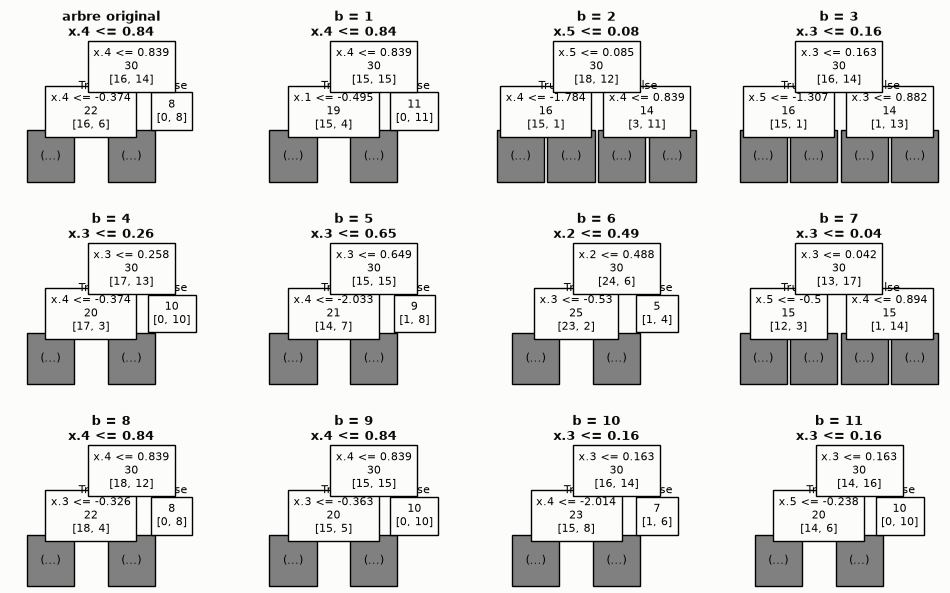

In [4]:
boot_idx = inf.bootstrap_indices(30, 11, rng)
trees_fig = [orig_tree] + [fit_tree(X_tr[i], y_tr[i]) for i in boot_idx]
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
names = ["x.%d" % (j + 1) for j in range(5)]
for k, (a, t) in enumerate(zip(axes.ravel(), trees_fig)):
    plot_tree(t, max_depth=1, feature_names=names, impurity=False, label="none",
              filled=False, ax=a, fontsize=8, proportion=False)
    j, s = t.tree_.feature[0], t.tree_.threshold[0]
    a.set_title(("arbre original" if k == 0 else "b = %d" % k)
                + "\n%s <= %.2f" % (names[j], s), fontsize=9)
fig.subplots_adjust(hspace=0.5)
plt.show()

### Erreur test en fonction du nombre d'arbres (figure 8.10)

On construit 200 arbres bootstrap et l'on calcule, pour $b = 1, \dots, 200$, l'erreur
test du bagging des $b$ premiers arbres, par **vote** et par **moyenne des
probabilités**.

In [5]:
def tree_fit_proba(Xb, yb, Xe):
    return tree_proba(fit_tree(Xb, yb), Xe)

probas = inf.bootstrap_predictions(tree_fit_proba, X_tr, y_tr, X_te, 200, rng)
err_vote, err_prob = inf.bagging_error_curves(probas, y_te)
print("Après 200 arbres : vote %.3f, probabilités %.3f, arbre seul %.3f"
      % (err_vote[-1], err_prob[-1], err_orig))

Après 200 arbres : vote 0.263, probabilités 0.265, arbre seul 0.295


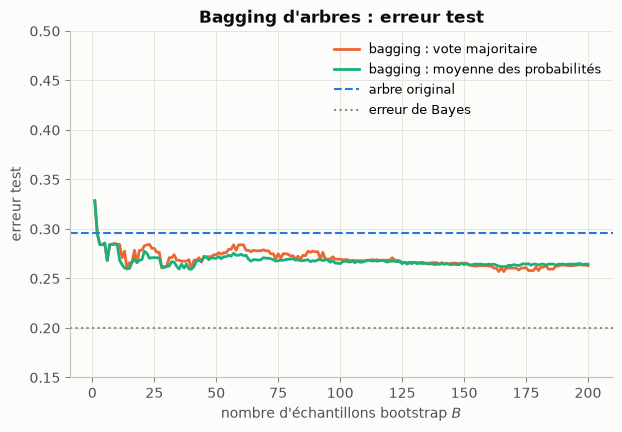

In [6]:
bs = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(bs, err_vote, color=ORANGE, label="bagging : vote majoritaire")
ax.plot(bs, err_prob, color=COLORS[2], label="bagging : moyenne des probabilités")
ax.axhline(err_orig, color=BLUE, ls="--", lw=1.5, label="arbre original")
ax.axhline(0.2, color=GRAY, ls=":", lw=1.5, label="erreur de Bayes")
ax.set(title="Bagging d'arbres : erreur test", xlabel="nombre d'échantillons bootstrap $B$",
       ylabel="erreur test", ylim=(0.15, 0.5))
ax.legend()
plt.show()

Une seule courbe dépend beaucoup de l'échantillon d'apprentissage tiré. Moyennons
l'expérience sur 20 échantillons d'apprentissage indépendants.

In [7]:
R, Bmax = 20, 100
E_orig, E_vote, E_prob = [], [], []
for r in range(R):
    Xr, yr = simulate_trees_data(30, rng)
    E_orig.append(np.mean(fit_tree(Xr, yr).predict(X_te) != y_te))
    pr = inf.bootstrap_predictions(tree_fit_proba, Xr, yr, X_te, Bmax, rng)
    ev, ep = inf.bagging_error_curves(pr, y_te)
    E_vote.append(ev); E_prob.append(ep)
E_vote, E_prob = np.mean(E_vote, 0), np.mean(E_prob, 0)

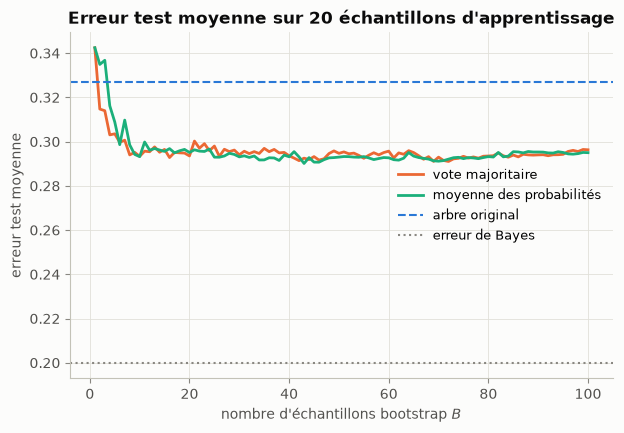

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, Bmax + 1), E_vote, color=ORANGE, label="vote majoritaire")
ax.plot(np.arange(1, Bmax + 1), E_prob, color=COLORS[2], label="moyenne des probabilités")
ax.axhline(np.mean(E_orig), color=BLUE, ls="--", lw=1.5, label="arbre original")
ax.axhline(0.2, color=GRAY, ls=":", lw=1.5, label="erreur de Bayes")
ax.set(title="Erreur test moyenne sur 20 échantillons d'apprentissage",
       xlabel="nombre d'échantillons bootstrap $B$", ylabel="erreur test moyenne")
ax.legend()
plt.show()

En moyenne, le bagging réduit l'erreur de l'arbre seul de plusieurs points, l'essentiel
du gain étant acquis dès quelques dizaines d'arbres ; vote et moyenne des probabilités
donnent ici des résultats voisins. L'erreur reste loin de l'erreur de Bayes : avec
seulement 30 observations, les arbres sont très instables, et la forte corrélation entre
variables les fait souvent couper sur $x_2, \dots, x_5$ plutôt que sur $x_1$.

### Pourquoi le bagging aide en perte quadratique

Soit $P$ la loi (inconnue) des données et l'agrégat « idéal »
$f_{\text{ag}}(x) = E_P\hat f^*(x)$, où $\hat f^*$ est ajusté sur un échantillon tiré
**selon $P$** (et non selon $\hat P$). Pour $x$ fixé, en insérant $f_{\text{ag}}(x)$ :

$$\begin{aligned}
E_P[Y - \hat f^*(x)]^2 &= E_P[Y - f_{\text{ag}}(x) + f_{\text{ag}}(x) - \hat f^*(x)]^2 \\
&= E_P[Y - f_{\text{ag}}(x)]^2 + E_P[\hat f^*(x) - f_{\text{ag}}(x)]^2
   \ge E_P[Y - f_{\text{ag}}(x)]^2. \qquad \text{(éq. (8.52))}
\end{aligned}$$

Le double produit est nul car $Y$ (nouvelle observation) est indépendant de $\hat f^*$ et
$E_P[\hat f^*(x) - f_{\text{ag}}(x)] = 0$ par définition de $f_{\text{ag}}$. L'écart est
exactement la **variance** de $\hat f^*(x)$ : l'agrégation sur la population ne dégrade
jamais l'erreur quadratique. Le bagging, qui tire dans $\hat P$ au lieu de $P$, en est une
approximation.

Vérifions-le sur un arbre de régression (profond, donc très variable) : pour
$f(x) = \sin(4x)$, $x \sim \mathcal U[0,1]$, $\sigma = 0{,}5$, $N = 50$, on estime biais et
variance en chaque point d'une grille sur 100 échantillons d'apprentissage.

In [9]:
f_reg = lambda t: np.sin(4 * t)
xg = np.linspace(0.02, 0.98, 60)[:, None]
def reg_tree(Xb, yb, Xe):
    return DecisionTreeRegressor(min_samples_leaf=2, random_state=0).fit(Xb, yb).predict(Xe)
single, bagged = [], []
for r in range(100):
    xr = rng.rand(50, 1); yr = f_reg(xr[:, 0]) + 0.5 * rng.randn(50)
    single.append(reg_tree(xr, yr, xg))
    bagged.append(inf.bootstrap_predictions(reg_tree, xr, yr, xg, 30, rng).mean(0))
single, bagged = np.array(single), np.array(bagged)
for name, P in [("arbre seul", single), ("arbre baggé", bagged)]:
    print("%-12s biais^2 moyen = %.4f   variance moyenne = %.4f"
          % (name, np.mean((P.mean(0) - f_reg(xg[:, 0])) ** 2), np.mean(P.var(0))))

arbre seul   biais^2 moyen = 0.0019   variance moyenne = 0.1531
arbre baggé  biais^2 moyen = 0.0012   variance moyenne = 0.0776


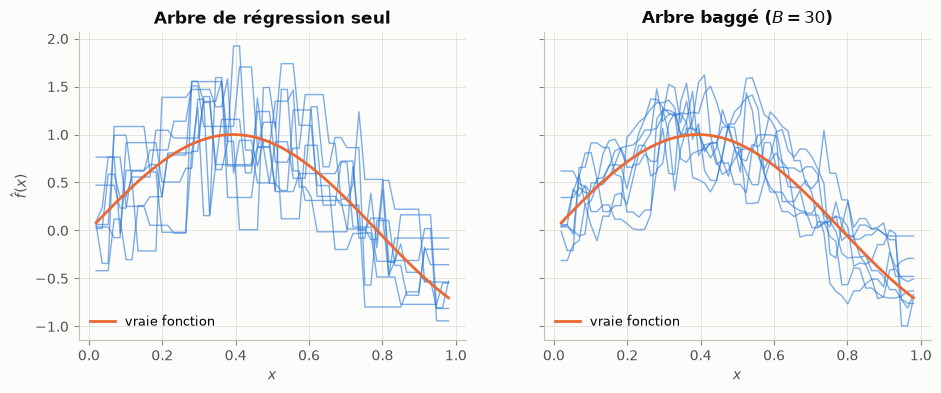

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, P, t in [(ax[0], single, "Arbre de régression seul"), (ax[1], bagged, "Arbre baggé ($B=30$)")]:
    for r in range(8):
        a.plot(xg[:, 0], P[r], color=BLUE, lw=1, alpha=0.6)
    a.plot(xg[:, 0], f_reg(xg[:, 0]), color=ORANGE, lw=2, label="vraie fonction")
    a.set(title=t, xlabel="$x$")
    a.legend(loc="lower left")
ax[0].set_ylabel(r"$\hat f(x)$")
plt.show()

### En perte 0-1, le bagging peut dégrader

Biais et variance ne s'additionnent plus en classification. Exemple du livre : $Y = 1$
pour tout $x$, et un classifieur aléatoire $\hat G$ qui prédit 1 (partout) avec
probabilité $0{,}4$ et 0 avec probabilité $0{,}6$. Son erreur vaut $0{,}6$ ; mais le vote
majoritaire de nombreux tirages prédit 0 presque sûrement : erreur $1$.

In [11]:
for B in [1, 11, 51, 201]:
    votes = rng.rand(20000, B) < 0.4                # chaque tirage prédit 1 avec proba 0,4
    print("B = %3d : erreur du vote majoritaire = %.3f" % (B, np.mean(votes.mean(1) <= 0.5)))

B =   1 : erreur du vote majoritaire = 0.608
B =  11 : erreur du vote majoritaire = 0.750
B =  51 : erreur du vote majoritaire = 0.927
B = 201 : erreur du vote majoritaire = 0.998


### La « sagesse des foules » (figure 8.11)

Inversement, si l'on vote entre classifieurs **indépendants** de taux d'erreur $e < 0{,}5$,
le nombre de votes corrects $S_1(x) \sim \mathrm{Bin}(B, 1 - e)$ et
$\Pr(S_1 > B/2) \to 1$ quand $B \to \infty$ (loi des grands nombres). Simulation du livre :
50 électeurs votent dans 10 catégories à 4 candidats ; dans chaque catégorie, 15 électeurs
tirés au hasard sont « informés » et choisissent le bon candidat avec probabilité $P$
(les autres candidats se partageant le reste), les 35 autres votent au hasard
($P = 0{,}25$ = aucune information).

In [12]:
def academy(P, rng, n_sim=50, voters=50, cats=10, nom=4, informed=15):
    cons, indiv = [], []
    for s in range(n_sim):
        ok_cons, ok_ind = 0, 0
        for c in range(cats):
            choice = rng.randint(0, nom, voters)        # candidat 0 = bon candidat
            inf_idx = rng.choice(voters, informed, replace=False)
            good = rng.rand(informed) < P
            choice[inf_idx] = np.where(good, 0, rng.randint(1, nom, informed))
            counts = np.bincount(choice, minlength=nom)
            winners = np.flatnonzero(counts == counts.max())
            ok_cons += rng.choice(winners) == 0          # égalités tirées au sort
            ok_ind += np.mean(choice == 0)
        cons.append(ok_cons); indiv.append(ok_ind)
    return np.mean(cons), np.std(cons), np.mean(indiv), np.std(indiv)

Ps = np.linspace(0.25, 1.0, 13)
res = np.array([academy(P, rng) for P in Ps])

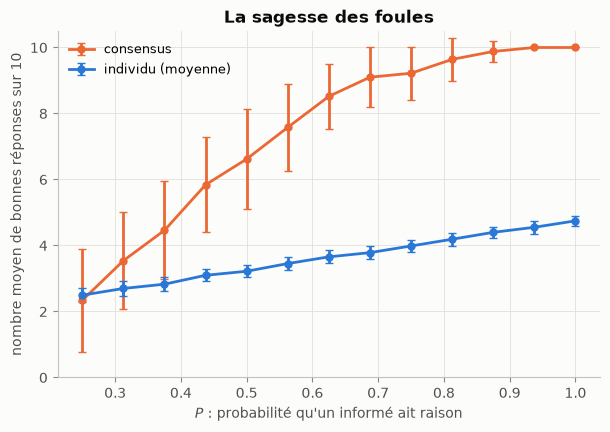

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(Ps, res[:, 0], yerr=res[:, 1], color=ORANGE, marker="o", capsize=3,
            label="consensus")
ax.errorbar(Ps, res[:, 2], yerr=res[:, 3], color=BLUE, marker="o", capsize=3,
            label="individu (moyenne)")
ax.set(title="La sagesse des foules", xlabel="$P$ : probabilité qu'un informé ait raison",
       ylabel="nombre moyen de bonnes réponses sur 10", ylim=(0, 10.5))
ax.legend()
plt.show()

Pour $P = 0{,}5$ par exemple, le consensus fait environ deux fois mieux qu'un individu.
Mais l'hypothèse cruciale est l'**indépendance** : les arbres baggés sont corrélés, ce que
les forêts aléatoires (chapitre 15) chercheront à réduire.

### Quand le bagging ne suffit pas (figure 8.12)

Deux classes dans $[0,1]^2$, séparées par la droite $x_1 + x_2 = 1$ ; 100 points
d'apprentissage. Le classifieur de base est une **souche** (*stump*) : une seule coupure
parallèle à un axe, choisie pour minimiser l'erreur d'apprentissage (codée à la main dans
`esl.ch08_inference.fit_stump`). On compare le bagging de 50 souches au **boosting**
(AdaBoost, chapitre 10) de souches.

In [14]:
def diag_data(n, rng):
    X = rng.rand(n, 2)
    return X, np.where(X.sum(1) > 1, 1, -1)

Xd, yd = diag_data(100, rng)
Xd_te, yd_te = diag_data(5000, rng)

def stump_fit_proba(Xb, yb, Xe):
    return inf.stump_proba(inf.fit_stump(Xb, yb), Xe)

bag_st = inf.bootstrap_predictions(stump_fit_proba, Xd, yd, Xd_te, 50, rng)
pred_bag = np.where((bag_st > 0.5).mean(0) > 0.5, 1, -1)       # vote majoritaire
stumps, alphas = inf.adaboost_stumps(Xd, yd, 400)
pred_boost = np.where(inf.adaboost_decision(stumps, alphas, Xd_te) > 0, 1, -1)
print("Erreur test : bagging de souches %.3f | boosting de souches %.3f"
      % (np.mean(pred_bag != yd_te), np.mean(pred_boost != yd_te)))

Erreur test : bagging de souches 0.175 | boosting de souches 0.060


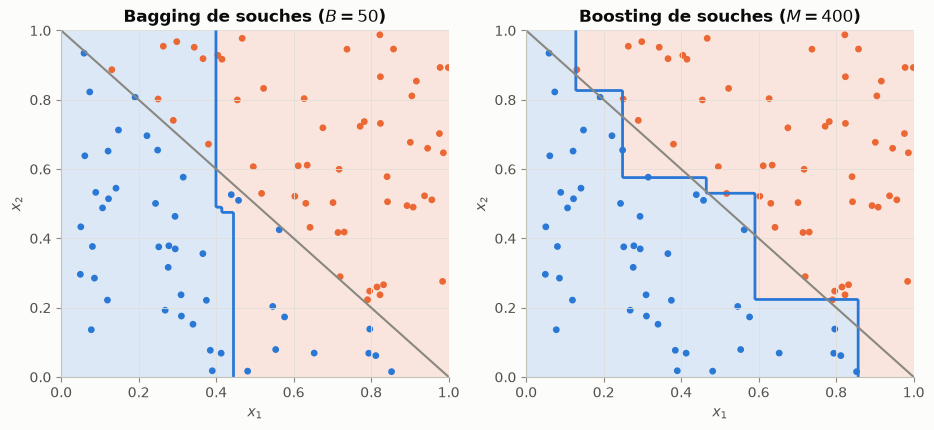

In [15]:
xx, yy, G = decision_grid((0, 1), (0, 1), 200)
bag_grid = (inf.bootstrap_predictions(stump_fit_proba, Xd, yd, G, 50,
                                       np.random.RandomState(1)) > 0.5).mean(0)
boost_grid = inf.adaboost_decision(stumps, alphas, G)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, Z, lev, t in [(ax[0], bag_grid, 0.5, "Bagging de souches ($B=50$)"),
                     (ax[1], boost_grid, 0.0, "Boosting de souches ($M=400$)")]:
    a.contourf(xx, yy, (Z > lev).reshape(xx.shape), levels=[-0.5, 0.5, 1.5], cmap=TWO_CLASS,
               alpha=0.15)
    a.contour(xx, yy, (Z > lev).reshape(xx.shape), levels=[0.5], colors=[BLUE])
    a.plot([0, 1], [1, 0], color=GRAY, lw=1.5)
    a.scatter(Xd[:, 0], Xd[:, 1], c=(yd > 0), cmap=TWO_CLASS, s=15)
    a.set(title=t, xlabel="$x_1$", ylabel="$x_2$")
plt.show()

Le bagging de souches ne fait qu'estimer la souche « moyenne » : sa frontière reste en
escalier grossier autour du centre. Le boosting, qui **élargit** réellement la classe de
modèles, approche la diagonale.

> **Remarque.** Un modèle baggé perd la structure simple du modèle de base : un arbre
> baggé n'est plus un arbre. Les méthodes stables (plus proches voisins, lisseurs
> linéaires) sont peu modifiées par le bagging.

## 2. Moyennage de modèles et stacking (section 8.8)

### Moyennage bayésien

Soit des modèles candidats $\mathcal M_1, \dots, \mathcal M_M$ et une quantité d'intérêt
$\zeta$ (par exemple une prédiction $f(x)$). Par la formule des probabilités totales :

$$\Pr(\zeta\mid Z) = \sum_{m=1}^M \Pr(\zeta\mid\mathcal M_m, Z)\Pr(\mathcal M_m\mid Z),
\qquad E(\zeta\mid Z) = \sum_{m=1}^M E(\zeta\mid\mathcal M_m, Z)\Pr(\mathcal M_m\mid Z).
\qquad \text{(éq. (8.53)-(8.54))}$$

La prédiction bayésienne est une moyenne pondérée par les probabilités a posteriori des
modèles, avec $\Pr(\mathcal M_m\mid Z) \propto \Pr(\mathcal M_m)\int
\Pr(Z\mid\theta_m, \mathcal M_m)\Pr(\theta_m\mid\mathcal M_m)\,d\theta_m$ (éq. (8.55)).
En pratique, on utilise souvent l'approximation BIC (section 7.7) :
$\Pr(\mathcal M_m\mid Z) \propto e^{-\mathrm{BIC}_m/2}$. Les **comités** donnent le même
poids à tous les modèles.

> **Remarque.** Vu sous l'angle de la section 8.4, le bagging est une moyenne a
> posteriori approchée, alors que $\hat f(x)$ en est le mode ; la moyenne a posteriori
> minimisant l'erreur quadratique, il n'est pas étonnant que le bagging la réduise.

### Point de vue fréquentiste et stacking

Étant donné des prédictions $\hat f_1(x), \dots, \hat f_M(x)$, on cherche les poids
$w = \arg\min_w E_P\big[Y - \sum_m w_m\hat f_m(x)\big]^2$ (éq. (8.56)) : c'est la
régression linéaire en population de $Y$ sur $\hat F(x) = (\hat f_1(x), \dots,
\hat f_M(x))^T$, $\hat w = E_P[\hat F\hat F^T]^{-1}E_P[\hat FY]$ (éq. (8.57)). Comme
chaque modèle seul correspond à un choix particulier de $w$, la combinaison optimale est
au moins aussi bonne que chacun (éq. (8.58)).

Remplacer l'espérance par une moyenne sur l'échantillon d'apprentissage est une mauvaise
idée : les modèles les plus complexes, qui collent le mieux aux données, reçoivent tout
le poids. Le **stacking** utilise à la place les prédictions **« leave-one-out »**
$\hat f_m^{-i}(x_i)$ (modèle $m$ ajusté sans l'observation $i$) :

$$\hat w^{\text{st}} = \arg\min_w \sum_{i=1}^N\Big[y_i - \sum_{m=1}^M w_m
\hat f_m^{-i}(x_i)\Big]^2. \qquad \text{(éq. (8.59))}$$

On peut imposer $w_m \ge 0$ et $\sum_m w_m = 1$ (problème quadratique sous contraintes).
Si l'on impose un seul poids égal à 1, on retrouve le choix du modèle par validation
croisée leave-one-out.

### Exemple : meilleurs sous-ensembles sur les données de cancer de la prostate

Reprenons l'exemple du livre : $\hat f_m$ est la régression linéaire sur le **meilleur
sous-ensemble de $m$ variables** ($m = 1, \dots, 8$) parmi les 8 prédicteurs des données
*prostate* (chapitre 3). On utilise l'échantillon d'apprentissage (67 patients) et l'on
évalue sur l'échantillon test (30 patients).

In [16]:
df = datasets.load_prostate()
feats = [c for c in df.columns if c not in ("lpsa", "train")]
tr, te = df[df.train], df[~df.train]
mean, sd = tr[feats].mean(), tr[feats].std()
Xp, yp = ((tr[feats] - mean) / sd).values, tr["lpsa"].values
Xp_te, yp_te = ((te[feats] - mean) / sd).values, te["lpsa"].values
Np, P = Xp.shape
print(Np, "observations d'apprentissage,", len(yp_te), "de test,", P, "variables")

67 observations d'apprentissage, 30 de test, 8 variables


Pour obtenir les prédictions leave-one-out **honnêtes**, il faut refaire la sélection du
meilleur sous-ensemble sans l'observation $i$. On utilise deux formules exactes de la
régression linéaire, avec $e_i$ le résidu et $h_{ii}$ le levier :

* résidu leave-one-out : $y_i - \hat f^{-i}(x_i) = e_i/(1 - h_{ii})$ ;
* somme des carrés sans l'observation $i$ : $\mathrm{RSS}_{-i} = \mathrm{RSS} -
  e_i^2/(1 - h_{ii})$.

Tout se calcule donc à partir des $2^8 - 1 = 255$ ajustements sur données complètes.

In [17]:
subsets, rss, loo_res, fits_te = [], [], [], []
for m in range(1, P + 1):
    for S in combinations(range(P), m):
        S = list(S)
        fitted, lr = inf.loo_residuals_linear(Xp[:, S], yp)
        subsets.append(S); rss.append(np.sum((yp - fitted) ** 2)); loo_res.append(lr)
        Xc = np.column_stack([np.ones(Np), Xp[:, S]])
        b = np.linalg.lstsq(Xc, yp, rcond=None)[0]
        fits_te.append((np.column_stack([np.ones(len(yp_te)), Xp_te[:, S]]) @ b, fitted))
sizes = np.array([len(S) for S in subsets]); rss = np.array(rss); loo_res = np.array(loo_res)
e = np.array([yp - f[1] for f in fits_te])                       # résidus (n_sub, N)
rss_minus_i = rss[:, None] - e * loo_res                         # e^2/(1-h) = e * loo_res

In [18]:
F_fit = np.zeros((Np, P)); F_loo = np.zeros((Np, P)); F_te = np.zeros((len(yp_te), P))
for m in range(1, P + 1):
    cand = np.flatnonzero(sizes == m)
    best = cand[np.argmin(rss[cand])]                            # sélection sur tout l'échantillon
    F_fit[:, m - 1] = fits_te[best][1]
    F_te[:, m - 1] = fits_te[best][0]
    best_i = cand[np.argmin(rss_minus_i[cand], axis=0)]          # sélection sans l'observation i
    F_loo[:, m - 1] = yp - loo_res[best_i, np.arange(Np)]
print("Meilleurs sous-ensembles :", [[feats[j] for j in subsets[c]][:3]
      for c in [np.flatnonzero(sizes == m)[np.argmin(rss[sizes == m])] for m in (1, 2, 3)]])

Meilleurs sous-ensembles : [['lcavol'], ['lcavol', 'lweight'], ['lcavol', 'lweight', 'svi']]


In [19]:
w_naive = inf.stacking_weights(F_fit, yp, "none")
w_st = inf.stacking_weights(F_loo, yp, "none")
w_st_simplex = inf.stacking_weights(F_loo, yp, "simplex")
cv_err = np.mean((yp[:, None] - F_loo) ** 2, axis=0)
print("taille m          :", np.arange(1, P + 1))
print("poids naïfs       :", np.round(w_naive, 2))
print("stacking libre    :", np.round(w_st, 2))
print("stacking simplexe :", np.round(w_st_simplex, 2))
print("erreur LOO par m  :", np.round(cv_err, 3))

taille m          : [1 2 3 4 5 6 7 8]
poids naïfs       : [-0. -0.  0. -0. -0.  0. -0.  1.]
stacking libre    : [ 0.22  0.09  0.1   0.99 -2.65  1.67  5.42 -4.86]
stacking simplexe : [0.17 0.   0.   0.15 0.   0.02 0.65 0.  ]
erreur LOO par m  : [0.707 0.651 0.7   0.583 0.753 0.569 0.564 0.584]


Comme annoncé, la régression sur les valeurs ajustées met (presque) tout le poids sur le
plus grand modèle. Le stacking répartit les poids selon la qualité **prédictive** des
modèles. Comparons les erreurs test.

In [20]:
m_cv = np.argmin(cv_err)
test_err = {
    "modèle complet (m = 8)": np.mean((yp_te - F_te[:, -1]) ** 2),
    "choix par LOO (m = %d)" % (m_cv + 1): np.mean((yp_te - F_te[:, m_cv]) ** 2),
    "comité (poids égaux)": np.mean((yp_te - F_te.mean(1)) ** 2),
    "stacking libre": np.mean((yp_te - F_te @ w_st) ** 2),
    "stacking simplexe": np.mean((yp_te - F_te @ w_st_simplex) ** 2),
}
for k, v in test_err.items():
    print("%-26s erreur test = %.3f" % (k, v))

modèle complet (m = 8)     erreur test = 0.521
choix par LOO (m = 7)      erreur test = 0.517
comité (poids égaux)       erreur test = 0.452
stacking libre             erreur test = 0.610
stacking simplexe          erreur test = 0.471


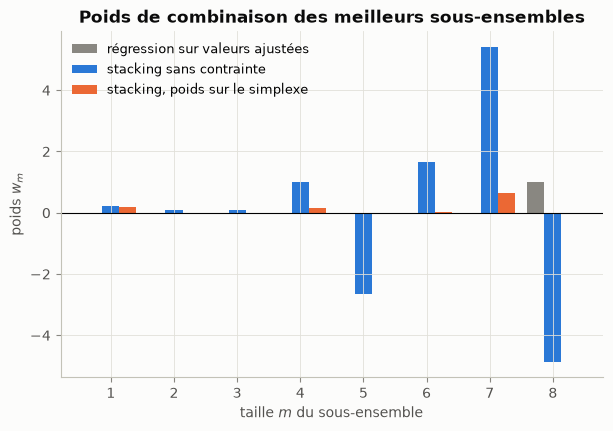

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
wd = 0.27
ms = np.arange(1, P + 1)
ax.bar(ms - wd, w_naive, wd, color=GRAY, label="régression sur valeurs ajustées")
ax.bar(ms, w_st, wd, color=BLUE, label="stacking sans contrainte")
ax.bar(ms + wd, w_st_simplex, wd, color=ORANGE, label="stacking, poids sur le simplexe")
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Poids de combinaison des meilleurs sous-ensembles",
       xlabel="taille $m$ du sous-ensemble", ylabel="poids $w_m$")
ax.legend()
plt.show()

Sans contrainte, les poids de stacking sont très instables (grands poids de signes
opposés sur des modèles presque colinéaires) et l'erreur test se dégrade. Imposer des
poids positifs de somme 1, comme le recommande le livre, stabilise la combinaison, qui
fait alors mieux que le modèle choisi par validation croisée. Sur un échantillon test
aussi petit (30 patients), ces écarts restent toutefois à interpréter avec prudence. Plus
généralement, on peut « empiler » n'importe quelle méthode d'apprentissage par-dessus les
prédictions de base, avec des poids qui dépendent éventuellement de $x$.

## 3. Recherche stochastique : le bumping (section 8.9)

Le bumping ne moyenne pas : il cherche un **meilleur modèle unique**. On ajuste le
modèle sur des échantillons bootstrap $Z^{*1}, \dots, Z^{*B}$ (plus l'échantillon
original), puis on garde celui qui a la plus petite erreur **sur l'échantillon
d'apprentissage original** :

$$\hat b = \arg\min_b \sum_{i=1}^N \big[y_i - \hat f^{*b}(x_i)\big]^2. \qquad
\text{(éq. (8.60))}$$

> **Intuition.** Perturber les données déplace la procédure d'ajustement dans l'espace
> des modèles ; si quelques points piègent l'algorithme dans une mauvaise solution, un
> échantillon bootstrap qui les omet peut l'en sortir. Les modèles comparés doivent avoir
> la **même complexité** (ici, le même nombre de feuilles).

### Exemple : le problème du « ou exclusif » (figure 8.13)

Deux classes dans $[-1, 1]^2$, avec $Y = 1$ si $x_1x_2 > 0$ (interaction pure). Couper en
$x_1 = 0$ puis en $x_2 = 0$ classerait parfaitement, mais l'algorithme glouton CART ne
voit aucune première coupure utile (toutes paraissent inutiles à cause de l'équilibre des
classes) et choisit presque au hasard. On compare un arbre à 4 feuilles ordinaire et un
arbre à 4 feuilles « bumpé » sur 20 échantillons bootstrap.

In [22]:
def xor_data(n, rng):
    X = rng.uniform(-1, 1, (n, 2))
    return X, (X[:, 0] * X[:, 1] > 0).astype(int)

Xx, yx = xor_data(200, rng)
fit4 = lambda Xb, yb: DecisionTreeClassifier(max_leaf_nodes=4, random_state=0).fit(Xb, yb)
train_err = lambda t, X, y: np.mean(t.predict(X) != y)
regular = fit4(Xx, yx)
bumped, b_hat, losses = inf.bumping(fit4, train_err, Xx, yx, 20, rng)
print("Erreur d'apprentissage : arbre ordinaire %.3f, arbre bumpé %.3f (échantillon b = %d)"
      % (losses[0], losses[b_hat], b_hat))

Erreur d'apprentissage : arbre ordinaire 0.430, arbre bumpé 0.080 (échantillon b = 13)
